# 03 · Experimental Causal Analysis

**Question:** does contacting a customer with the retention campaign change their probability of
churning, and by how much?

## Potential outcomes

For each customer *i*:

* `Yᵢ(1)` = churn outcome **if contacted**
* `Yᵢ(0)` = churn outcome **if not contacted**
* individual treatment effect `ITEᵢ = Yᵢ(1) − Yᵢ(0)`

Only one of the two potential outcomes is observed for each customer. A contacted customer's
`Y(0)` is a counterfactual that never happened. This is the **fundamental problem of causal
inference**, and it means individual effects can never be observed directly.

Population averages *can* be estimated. The **average treatment effect**

`ATE = E[Y(1) − Y(0)]`

is identified by `E[Y | T=1] − E[Y | T=0]` **if treatment is independent of the potential
outcomes**, which is what randomisation guarantees. Notebooks 01–02 showed that the treated
share varies across segments, so this notebook estimates the ATE twice. The first estimate is the
simple difference in means, which is valid under complete randomisation. The second set adjusts for
covariates, which is valid under the weaker assumption that assignment is random *given X*.

Because `y = 1` is churn, a **negative ATE means the campaign reduces churn**.

In [1]:
import json
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_confint

from src.functions import (BLUE, GREY, INK_2, ORANGE, OUTCOME, TREATMENT, aipw_ate,
                           ate_diff_in_means, bootstrap_ci, feature_lists, ipw_weights,
                           load_data, make_gbm_classifier, make_logit, make_preprocessor,
                           make_propensity_model, oof_predict_proba, savefig, set_style,
                           t_learner, weighted_smd)

set_style()
df = load_data()
num, cat = feature_lists(df)
t, y = df[TREATMENT].to_numpy(), df[OUTCOME].to_numpy()
PROCESSED = ROOT / "data" / "processed"
PROCESSED.mkdir(parents=True, exist_ok=True)

## 1. Difference in means

In [2]:
r = ate_diff_in_means(y, t)
pd.Series({
    "churn rate, control": f"{r['churn_control']:.2%}  (n={r['n_control']:,})",
    "churn rate, treated": f"{r['churn_treated']:.2%}  (n={r['n_treated']:,})",
    "ATE (risk difference)": f"{100 * r['ate']:+.2f} pp",
    "95% CI (Newcombe)": f"[{100 * r['ci_newcombe'][0]:+.2f}, {100 * r['ci_newcombe'][1]:+.2f}] pp",
    "95% CI (Wald)": f"[{100 * r['ci_wald'][0]:+.2f}, {100 * r['ci_wald'][1]:+.2f}] pp",
    "two-proportion z-test": f"z = {r['z']:.2f},  p = {r['p_value']:.2f}",
    "risk ratio (95% CI)": f"{r['risk_ratio']:.2f}  [{r['rr_ci'][0]:.2f}, {r['rr_ci'][1]:.2f}]",
    "Cohen's h": f"{r['cohens_h']:.3f}",
}, name="value").to_frame()

,value
"churn rate, control","3.64% (n=2,886)"
"churn rate, treated","3.36% (n=9,010)"
ATE (risk difference),-0.28 pp
95% CI (Newcombe),"[-1.10, +0.46] pp"
95% CI (Wald),"[-1.05, +0.50] pp"
two-proportion z-test,"z = -0.71, p = 0.48"
risk ratio (95% CI),"0.92 [0.74, 1.15]"
Cohen's h,-0.015


A bootstrap that resamples within each arm (holding arm sizes fixed, as in the experiment) gives
a distribution-free check on the interval.

In [3]:
lo, hi, draws = bootstrap_ci(lambda yy, tt: yy[tt == 1].mean() - yy[tt == 0].mean(),
                             y, t, n_boot=5000, stratify=t, seed=1)
print(f"Bootstrap 95% CI: [{100 * lo:+.2f}, {100 * hi:+.2f}] pp")
print(f"Share of bootstrap draws below zero (campaign reduces churn): {(draws < 0).mean():.0%}")

Bootstrap 95% CI: [-1.06, +0.49] pp
Share of bootstrap draws below zero (campaign reduces churn): 75%


**Reading the result**

* Contacted customers churned at **3.36%** vs **3.64%** for the control group, a
  difference of **−0.28 percentage points** (≈ 8% relative reduction).
* The 95% confidence interval runs from about **−1.1 pp to +0.5 pp**. It includes zero and
  effects of *either* sign. The p-value of 0.48 means a difference this large would be unremarkable
  if the campaign had no effect at all.
* **Not statistically significant ≠ "the campaign doesn't work".** The data is consistent with
  a meaningful benefit (a 1 pp reduction would be ~30% fewer churners), with no effect, and with
  a small harm. The experiment cannot distinguish between them. Section 2 explains why.

## 2. Statistical power: what *could* this experiment detect?

In [4]:
power = NormalIndPower()
ratio = r["n_treated"] / r["n_control"]
p0 = r["churn_control"]

h_mde = power.solve_power(nobs1=r["n_control"], ratio=ratio, alpha=0.05, power=0.8)
p1_mde = np.sin(np.arcsin(np.sqrt(p0)) - h_mde / 2) ** 2
achieved = power.power(effect_size=abs(r["cohens_h"]), nobs1=r["n_control"], ratio=ratio, alpha=0.05)
n_needed = power.solve_power(effect_size=abs(r["cohens_h"]), power=0.8, alpha=0.05, ratio=1)

pd.Series({
    "minimum detectable effect (80% power, α=0.05)": f"{100 * (p0 - p1_mde):.2f} pp  "
                                                    f"(control {p0:.2%} → treated {p1_mde:.2%})",
    "MDE as relative churn reduction": f"{(p0 - p1_mde) / p0:.0%}",
    "power to detect the observed −0.28 pp": f"{achieved:.0%}",
    "customers per arm needed for 80% power at −0.28 pp": f"{n_needed:,.0f}",
}, name="value").to_frame()

,value
"minimum detectable effect (80% power, α=0.05)",1.04 pp (control 3.64% → treated 2.60%)
MDE as relative churn reduction,29%
power to detect the observed −0.28 pp,11%
customers per arm needed for 80% power at −0.28 pp,"69,928"


With these arm sizes and a 3.6% base rate, the experiment had 80% power only for effects of
about **−1.0 pp or larger** (a ~29% relative reduction in churn). The observed effect is about a
quarter of that, and the experiment had only **~11% power** to detect an effect of that size. Detecting
it reliably would need roughly **70,000 customers per arm**. The non-significant result is
therefore *expected* even if the campaign has a real, modest benefit. This shapes everything that
follows. Heterogeneity analysis splits the same data into smaller groups, so it will be **even
more** underpowered.

## 3. Was assignment random? A formal check

If treatment were completely randomised, no function of the covariates could predict who was
treated, and a classifier's out-of-sample AUC for predicting `t` from `X` would be ≈ 0.5.

Several propensity-score specifications are compared below. The choice between them is made on
**covariate balance after weighting**, not on outcomes. This is design-stage work: `y` is never
looked at, which avoids choosing the specification that gives a preferred answer.

In [5]:
X_all = make_preprocessor(num, cat).fit_transform(df)
X_fac = make_preprocessor([], cat).fit_transform(df)
Xd = pd.concat([df[num], pd.get_dummies(df[cat], prefix_sep="=").astype(float)], axis=1)
Xd = Xd.loc[:, Xd.std() > 0]

def balance_summary(w):
    s = weighted_smd(Xd, t, w).abs()
    return {"max |SMD|": s.max(), "# |SMD|>0.1": int((s > 0.1).sum()), "mean |SMD|": s.mean()}

specs = {
    "logistic · factors only": (lambda: LogisticRegression(C=0.1, max_iter=3000), X_fac),
    "logistic · all features": (lambda: make_logit(0.01), X_all),
    "gradient boosting · all features": (make_propensity_model, X_all),
}
rows, propensities = [], {}
for name, (model, X) in specs.items():
    e_ = oof_predict_proba(model, X, t, n_splits=5, seed=0)
    propensities[name] = e_
    rows.append({"specification": name, "out-of-fold AUC": roc_auc_score(t, e_),
                 "e: 1st pct": np.quantile(e_, 0.01), "e: 99th pct": np.quantile(e_, 0.99),
                 **balance_summary(ipw_weights(t, e_))})
rows.insert(0, {"specification": "(no weighting)", **balance_summary(None)})
pd.DataFrame(rows).set_index("specification").round(3)

,max |SMD|,# |SMD|>0.1,mean |SMD|,out-of-fold AUC,e: 1st pct,e: 99th pct
specification,,,,,,
(no weighting),0.364,20,0.035,NaN,NaN,NaN
logistic · factors only,0.142,2,0.019,0.615,0.555,0.932
logistic · all features,0.380,13,0.027,0.641,0.428,0.962
gradient boosting · all features,0.088,0,0.020,0.651,0.535,0.936


* Every specification predicts treatment better than chance (**AUC ≈ 0.61–0.65**). Assignment is
  **not** completely random across the pooled data.
* The logistic model on all 300+ features chases noise. A few customers get propensities near
  0 or 1, and weighting by them leaves *worse* balance than no weighting.
* The regularised **gradient-boosting** model gives the best balance (all |SMD| < 0.1 after
  weighting) with good overlap: 98% of customers had between a ~54% and a ~94% estimated chance
  of being treated. It is used as the propensity model from here on (`make_propensity_model`).
* Good overlap matters. Every type of customer appears in both arms, so the adjusted
  comparisons below compare like with like rather than extrapolate.

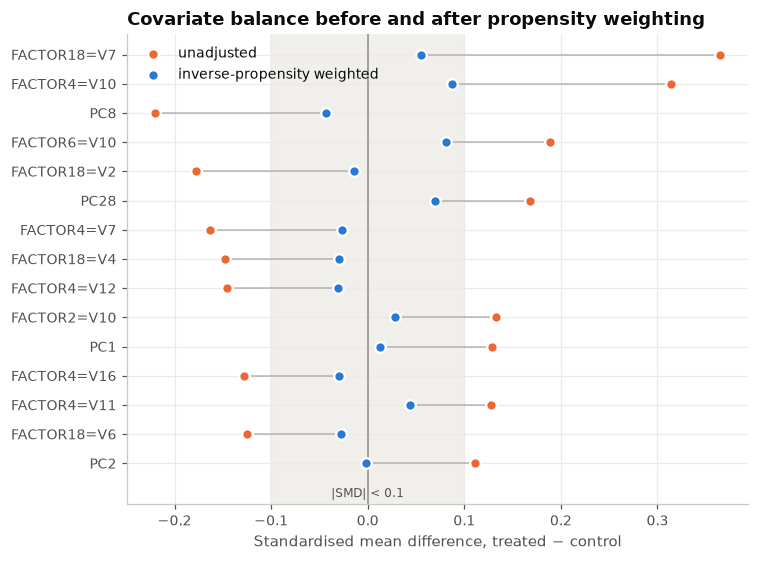

In [6]:
e = propensities["gradient boosting · all features"]
w = ipw_weights(t, e)

smd_raw = weighted_smd(Xd, t)
smd_w = weighted_smd(Xd, t, w)
top = smd_raw.abs().sort_values(ascending=False).head(15).index[::-1]

fig, ax = plt.subplots(figsize=(7, 5.2))
ypos = np.arange(len(top))
ax.axvspan(-0.1, 0.1, color="#f0efec", zorder=0)
ax.axvline(0, color=GREY, linewidth=1)
ax.hlines(ypos, smd_raw[top], smd_w[top], color=GREY, linewidth=1, alpha=0.6)
ax.scatter(smd_raw[top], ypos, color=ORANGE, s=48, zorder=3, edgecolor="white", linewidth=1.5,
           label="unadjusted")
ax.scatter(smd_w[top], ypos, color=BLUE, s=48, zorder=3, edgecolor="white", linewidth=1.5,
           label="inverse-propensity weighted")
ax.set_yticks(ypos, top)
ax.set_xlabel("Standardised mean difference, treated − control")
ax.set_title("Covariate balance before and after propensity weighting")
ax.text(0, -1.05, "|SMD| < 0.1", ha="center", va="center", fontsize=8, color=INK_2)
ax.legend(loc="upper left")
ax.set_ylim(-1.4, len(top) - 0.3)
plt.tight_layout()
savefig(fig, "fig3_covariate_balance")

**Reading the figure.** The 15 most imbalanced covariates are shown (out of 330 covariates and
levels). Orange dots are raw treated-minus-control differences, and blue dots are the same after
re-weighting each arm by the inverse probability of the treatment it received. Weighting moves
every covariate into the conventional ±0.1 band, so the weighted arms resemble a randomised
comparison on all observed characteristics.

## 4. Covariate-adjusted ATE estimates

| Estimator | Idea | Valid if |
|---|---|---|
| Difference in means | compare raw arm averages | assignment completely random |
| Post-stratified on `FACTOR18` | average within-segment differences, weighted by segment size | assignment random within `FACTOR18` segments |
| IPW (Hájek) | re-weight arms by 1 / propensity | propensity model correct |
| AIPW (doubly robust) | outcome model + IPW correction of its residuals | propensity **or** outcome model correct |

All models are **cross-fitted**: each customer's propensity and predicted outcomes come from models
that never saw that customer.

In [7]:
def stratified_ate(y, t, s):
    d = pd.DataFrame({"y": y, "t": t, "s": s})
    g = d.groupby("s").apply(lambda q: pd.Series({
        "n": len(q), "diff": q[q.t == 1].y.mean() - q[q.t == 0].y.mean(),
        "var": q[q.t == 1].y.var() / (q.t == 1).sum() + q[q.t == 0].y.var() / (q.t == 0).sum()}),
        include_groups=False)
    wts = g.n / g.n.sum()
    return float((wts * g["diff"]).sum()), float(np.sqrt((wts**2 * g["var"]).sum()))

def hajek(y, t, w):
    return np.average(y[t == 1], weights=w[t == 1]) - np.average(y[t == 0], weights=w[t == 0])

z = stats.norm.ppf(0.975)
est = [{"estimator": "Difference in means", "ate": r["ate"], "lo": r["ci_newcombe"][0], "hi": r["ci_newcombe"][1]}]

ate_s, se_s = stratified_ate(y, t, df["FACTOR18"])
est.append({"estimator": "Post-stratified (FACTOR18)", "ate": ate_s, "lo": ate_s - z * se_s, "hi": ate_s + z * se_s})

ate_ipw = hajek(y, t, w)
lo_ipw, hi_ipw, ipw_draws = bootstrap_ci(lambda yy, tt, ww: hajek(yy, tt, ww), y, t, w, n_boot=2000, seed=2)
est.append({"estimator": "IPW (Hájek)", "ate": ate_ipw, "lo": lo_ipw, "hi": hi_ipw,
            "p": 2 * stats.norm.sf(abs(ate_ipw / ipw_draws.std(ddof=1)))})

for label, model in [("AIPW · logistic outcome", lambda: make_logit(0.01)),
                     ("AIPW · gradient-boosting outcome", make_gbm_classifier)]:
    mu0, mu1, _ = t_learner(model, X_all, t, y, n_splits=5, seed=0)
    a = aipw_ate(y, t, e, mu0, mu1)
    est.append({"estimator": label, "ate": a["ate"], "lo": a["ci"][0], "hi": a["ci"][1], "p": a["p_value"]})

est = pd.DataFrame(est)
est.loc[0, "p"] = r["p_value"]
est.loc[1, "p"] = 2 * stats.norm.sf(abs(ate_s / se_s))
(est.assign(**{c: 100 * est[c] for c in ["ate", "lo", "hi"]})
    .rename(columns={"ate": "ATE (pp)", "lo": "95% CI low", "hi": "95% CI high", "p": "p-value"})
    .set_index("estimator").round(3))

,ATE (pp),95% CI low,95% CI high,p-value
estimator,,,,
Difference in means,-0.275,-1.102,0.462,0.479
Post-stratified (FACTOR18),-0.245,-1.041,0.552,0.547
IPW (Hájek),-0.140,-0.928,0.624,0.726
AIPW · logistic outcome,-0.178,-0.957,0.601,0.654
AIPW · gradient-boosting outcome,-0.125,-0.895,0.646,0.751


**Interpretation.** Adjusting for the segment-dependent assignment does not change the
conclusion. All five point estimates are small and negative, between **−0.28 and −0.13 pp**. Every
interval spans zero, and the intervals have similar width (about ±0.8 pp). The adjusted estimates
are somewhat closer to zero than the naive one, so part of the naive difference may reflect *who*
was treated rather than the treatment, but the shift is well within the noise. The imbalance found in notebooks 01–02 is
real, but it is not strongly related to churn, so it biases the naive comparison very little.
The robust conclusion is:

> **There is no statistically detectable average effect of the retention contact on two-month
> churn.** The data rules out large effects. A churn reduction of more than about 1.1 pp, or an
> increase of more than about 0.65 pp, is outside every interval. It cannot rule out a modest benefit.

In [8]:
# Persist inputs for later notebooks (derived from licensed data -> git-ignored folder).
pd.DataFrame({"propensity": e}).to_parquet(PROCESSED / "propensity.parquet", index=False)
est.to_csv(PROCESSED / "ate_estimates_experimental.csv", index=False)

## 5. Figure: churn by arm

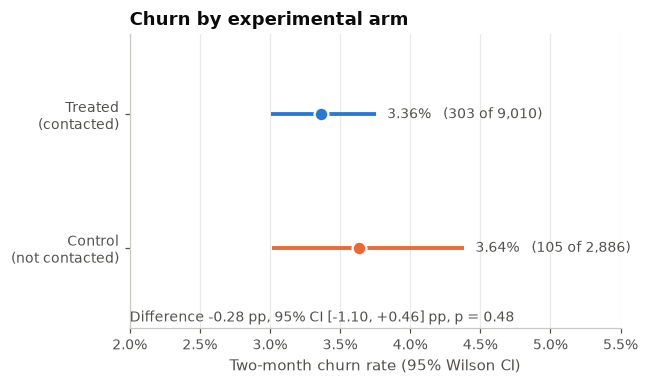

In [9]:
arms = pd.DataFrame({
    "arm": ["Control\n(not contacted)", "Treated\n(contacted)"],
    "rate": [r["churn_control"], r["churn_treated"]],
    "n": [r["n_control"], r["n_treated"]],
    "events": [int(y[t == 0].sum()), int(y[t == 1].sum())],
})
ci = np.array([proportion_confint(k, n, method="wilson") for k, n in zip(arms.events, arms.n)])

fig, ax = plt.subplots(figsize=(6, 3.6))
colors = [ORANGE, BLUE]
for i, row in arms.iterrows():
    ax.errorbar(row.rate, i, xerr=[[row.rate - ci[i, 0]], [ci[i, 1] - row.rate]], fmt="o",
                color=colors[i], markersize=9, capsize=0, elinewidth=2.5,
                markeredgecolor="white", markeredgewidth=1.5)
    ax.text(ci[i, 1] + 0.0008, i, f"{row.rate:.2%}   ({row.events} of {row.n:,})",
            va="center", fontsize=9, color=INK_2)
ax.set_yticks([0, 1], arms.arm)
ax.set_ylim(-0.6, 1.6)
ax.set_xlim(0.02, 0.055)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=1))
ax.set_xlabel("Two-month churn rate (95% Wilson CI)")
ax.set_title("Churn by experimental arm")
ax.grid(axis="y", visible=False)
ax.text(0.02, -0.55, f"Difference {100 * r['ate']:+.2f} pp, 95% CI "
        f"[{100 * r['ci_newcombe'][0]:+.2f}, {100 * r['ci_newcombe'][1]:+.2f}] pp, p = {r['p_value']:.2f}",
        fontsize=9, color=INK_2)
plt.tight_layout()
savefig(fig, "fig1_churn_by_arm")

**Reading the figure.** The two confidence intervals overlap almost completely. The treated arm's
interval is narrower because it has three times as many customers. The control arm, with only
105 churners, is the main source of uncertainty.

## Summary

| Question | Answer |
|---|---|
| Is there evidence the intervention changes churn? | **No statistically significant evidence** (p between 0.48 and 0.75 across estimators). |
| Direction? | Every point estimate is slightly negative (churn reduction), but the sign is not statistically established. |
| How large? | −0.28 pp (≈ −8% relative) naive; −0.25 to −0.13 pp adjusted. 95% intervals cover roughly −1.1 to +0.65 pp. |
| Practically meaningful? | A sustained 0.3 pp reduction would prevent ~3 churners per 1,000 contacts. Whether that pays depends on the cost of a call vs. customer value. The experiment was not powered to detect it. |
| Was assignment random? | Random **conditional on segment**, not unconditionally (propensity AUC ≈ 0.65). Adjustment changes little. |